# MNIST: Dense and Convolutional Models (M1 Series)

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 1 SIEC · 2023–2024 (inferred from neighboring numbered TP series; not explicitly in this source file)  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Compare densely connected networks to convolutional networks on handwritten digits.

**Approach:** Keras-based FCNN and CNN experiments.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


# TP 1 AI USING CNN
## GUERBOUZ MOHAMMED ALAA EDDINE

In [12]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Activation,Flatten,Conv2D,MaxPooling2D
import cv2 

# Loading " MNIST DATASETS "
## Contains 60k Training samples  , 10k  Testing Samples
### it is in the Metadata of the tensorFlow Library and Exactly from keras

In [13]:
mnist = tf.keras.datasets.mnist

## After Loading The MNIST data , Divide it into train and test datasets

In [14]:
(X_train,Y_train),(X_test,Y_test) = mnist.load_data()

In [15]:
X_train.shape

(60000, 28, 28)

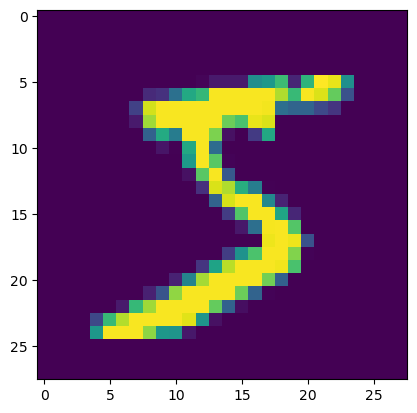

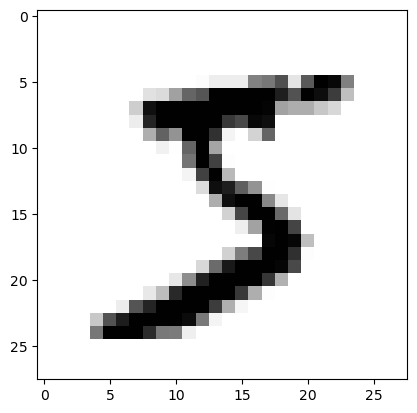

In [16]:
plt.imshow(X_train[0])
plt.show()
plt.imshow(X_train[0],cmap=plt.cm.binary)

## Checking the value of each pixels before normalization

In [17]:
print(X_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

## As image are in gray level 1(channel ==> 0 to 225) not colored (RGB)
# Normalizing The Data | Pre-Processing Step

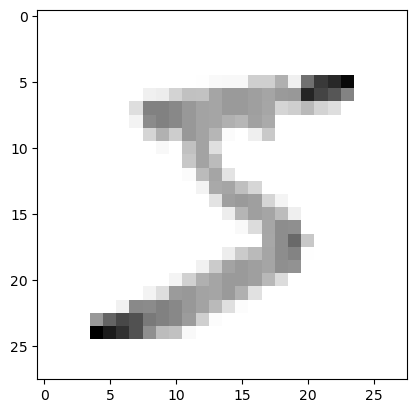

In [18]:
X_train = tf.keras.utils.normalize (X_train, axis=1)
X_test = tf.keras.utils.normalize  (X_test , axis=1)
plt.imshow(X_train[0], cmap = plt.cm.binary)

# After Normalization

## Resizing Image to make it suitable for apply Convenotional Operations

In [19]:
img_size= 28
x_trainer =np.array(X_train).reshape(-1,img_size,img_size,1)
x_tester = np.array(X_test).reshape(-1,img_size,img_size,1)
print("training sample dimension",x_trainer.shape)
print("testing sample dimension",x_tester.shape)

training sample dimension (60000, 28, 28, 1)
testing sample dimension (10000, 28, 28, 1)


# Creating The Deep Neural Networks
## Training On 60k Samples of MNIST handwritten dataset

In [20]:
#Creat a neural network Now

#------------------------------------------------------
### first Convolution Layer 0 1 2 3 (60000,28,28,1)
model = Sequential()
model.add(Conv2D(64,(3,3),input_shape = x_trainer.shape[1:])) # only for first Convlution layer  to mention input Layer Size 
model.add(Activation("relu"))# Activvation function to make it non linear ,
model.add(MaxPooling2D(pool_size=(2)))##MaxPooling single maximum values oif 2x2


#------------------------------------------------------
### Seconde Convolution Layer
model.add(Conv2D(64,(3,3)))
model.add(Activation("relu")) 
model.add(MaxPooling2D(pool_size=(2))) 
#------------------------------------------------------


#------------------------------------------------------
### Third Convolution Layer
model.add(Conv2D(64,(3,3))) # 24 x 24
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2)))

#------------------------------------------------------
### Fully Connected Layer #1 20x20 =400
model.add(Flatten()) # Before using the fully Connected layer  need to be flatten so that 2d to 1d
model.add(Dense(64)) # 
model.add(Activation("relu"))

### Fully Connected Layer #2
model.add(Dense(32))
model.add(Activation("relu"))
### last Fully Connected Layer #3 , output must  be equal to number of classes , 10(0-9)
model.add(Dense(10)) # This last danse layer must be equal to 10
model.add(Activation('softmax')) #Activation function is changed to softmax '(Class Probabilities) 
#Binary classification , one neuron is Danse Layer ,sigmoid

In [21]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 64)        640       
                                                                 
 activation (Activation)     (None, 26, 26, 64)        0         
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 64)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        36928     
                                                                 
 activation_1 (Activation)   (None, 11, 11, 64)        0         
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                   

In [35]:
model.compile(loss="sparse_categorical_crossentropy",optimizer="adam",metrics=['accuracy'])

In [36]:
model.fit(x_trainer,Y_train,epochs=7,validation_split=0.3) # training my model 

Epoch 1/7
1313/1313 [==============================] - 22s 16ms/step - loss: 0.0285 - accuracy: 0.9901 - val_loss: 0.0675 - val_accuracy: 0.9822
Epoch 2/7
1313/1313 [==============================] - 20s 15ms/step - loss: 0.0216 - accuracy: 0.9928 - val_loss: 0.0819 - val_accuracy: 0.9765
Epoch 3/7
1313/1313 [==============================] - 20s 15ms/step - loss: 0.0189 - accuracy: 0.9941 - val_loss: 0.0650 - val_accuracy: 0.9841
Epoch 4/7
1313/1313 [==============================] - 21s 16ms/step - loss: 0.0213 - accuracy: 0.9927 - val_loss: 0.0664 - val_accuracy: 0.9833
Epoch 5/7
1313/1313 [==============================] - 22s 17ms/step - loss: 0.0133 - accuracy: 0.9957 - val_loss: 0.0758 - val_accuracy: 0.9822
Epoch 6/7
1313/1313 [==============================] - 22s 17ms/step - loss: 0.0137 - accuracy: 0.9955 - val_loss: 0.0637 - val_accuracy: 0.9858
Epoch 7/7
1313/1313 [==============================] - 22s 16ms/step - loss: 0.0137 - accuracy: 0.9959 - val_loss: 0.0603 - val_ac

## Evaluating on testing data set MNIT 

In [37]:
test_loss ,test_acc =model.evaluate(x_tester,Y_test)
print("Test Loss on 10,000 test sample",test_loss)
print("Validation Accuracy on 10,000 test sample",test_acc)

313/313 [==============================] - 1s 3ms/step - loss: 0.0630 - accuracy: 0.9871
Test Loss on 10,000 test sample 0.06297935545444489
Validation Accuracy on 10,000 test sample 0.9871000051498413


In [25]:
## Predict the X_test partt from the divided dataset

In [38]:
predections=model.predict([x_tester])

313/313 [==============================] - 1s 4ms/step


In [40]:
print(predections)

[[2.44468161e-12 8.82185347e-09 8.02830719e-11 ... 1.00000000e+00
  9.91065140e-14 4.64895622e-10]
 [1.19716617e-07 2.02367811e-09 9.99999523e-01 ... 3.95402378e-09
  8.38024050e-08 5.85837645e-09]
 [4.05187633e-10 1.00000000e+00 1.01504145e-10 ... 1.22419745e-08
  6.31390940e-10 2.84060486e-09]
 ...
 [2.53171139e-12 9.21840471e-09 1.44720356e-14 ... 1.50454399e-10
  2.55868077e-10 1.02064369e-07]
 [3.56786887e-12 5.06145491e-16 8.22903493e-17 ... 6.14294213e-15
  5.44173352e-11 4.08616608e-13]
 [7.60325474e-06 6.22312939e-07 8.99570125e-07 ... 2.62836420e-06
  8.81496908e-06 2.53106094e-07]]


In [41]:
print(np.argmax(predections[128]))

8


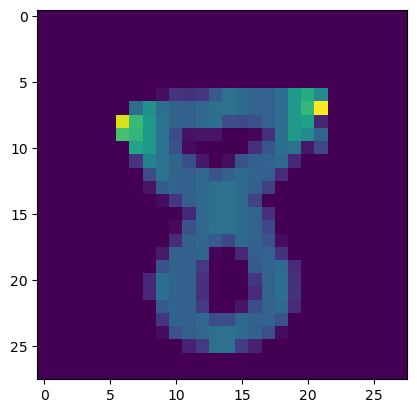

In [42]:
plt.imshow(X_test[128])

## Download the Image to be tested out by the model its dimension is 28x28

In [50]:
img = cv2.imread('test.jpg')

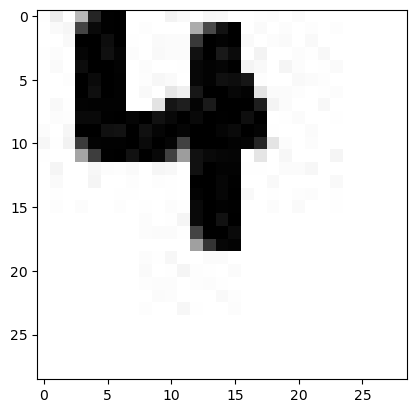

In [51]:
plt.imshow(img)

### As image are in gray level 1(channel ==> 0 to 225) not colored (RGB)
## Normalizing The Image | Pre-Processing Step

In [52]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

resized = cv2.resize(gray,(28,28), interpolation =cv2.INTER_AREA)

In [53]:
newimg =tf.keras.utils.normalize(resized, axis=1)

## Resizing the image

In [54]:
newimg = np.array(newimg).reshape(-1,28,28,1)

## Make predictions

In [55]:
p= model.predict(newimg)

1/1 [==============================] - 0s 13ms/step


## The prediction result

In [56]:
print(np.argmax(p))

0
